<H1>ResistorNetowrk</H1> 
skrf resistor network
<hr>
<H2>Modification history </H2><br> 
<table>
    <tr>
        <th> Modified </th>
        <th> By </th>
        <th> Reason </th>
    </tr>
    <tr> 
        <td> 06-Mar-26 </td>
        <td> CBL </td> 
        <td> Original </td>
    </tr>
</table>
<hr> 
<H2> References </H2> 
<a href = "https://scikit-rf.readthedocs.io/en/latest/tutorials/Circuit.html"> Example circuits </a><br> 
<a href = "https://onlinelibrary.wiley.com/doi/10.1002/mop.10983"> Microwave S-Parameter reduction </a><br>
<a href = "https://scikit-rf.readthedocs.io/en/latest/tutorials/Media.html"> RG58 example </a><br>
<a href = "https://scikit-rf.readthedocs.io/en/latest/api/media/generated/skrf.media.coaxial.Coaxial.html"> Coaxial </a><br>

<H2> Notes </H2>


In [2]:
# imports - package libraries etc. 
import numpy as np
import matplotlib.pyplot as plt
import skrf as rf
from skrf import Network
from skrf import Frequency
from skrf.circuit import Circuit
from skrf.tlineFunctions import INF
#
# skrf figure styling
rf.stylely()

In [3]:
# Setup a frequency array, Use the same values as Paul
#
f = np.array([7.841, 23.164, 69.2]) # in MHz
# Before creating the scikit-rf Network object, one must forge the Frequency and S-matrix:
freq = rf.Frequency.from_f(f, unit='MHz')

There are a lot of incomplete thoughts here

In [4]:
# https://scikit-rf.readthedocs.io/en/v1.8.0/examples/circuit/Lumped%20Element%20Circuits.html
# The example imports from an ansys designer tool. let do it manually
# Define my components here. 
# Frequency domain
scan_frequency = rf.Frequency(7.0, 64.0, 101, 'mhz')
# create a resistor
# https://scikit-rf.readthedocs.io/en/latest/api/generated/skrf.circuit.Circuit.SeriesImpedance.html
R0 = Circuit.SeriesImpedance(scan_frequency, INF, name='R0', z0=50.0)
#
R_val = 75.0 # ohms
R1 = Circuit.SeriesImpedance(scan_frequency, INF , name ='R1', z0=R_val)  # real ohms
#
# What does it mean to design a port? 
# https://scikit-rf.readthedocs.io/en/v1.8.0/api/generated/skrf.circuit.Circuit.Port.html
#
port1  = Circuit.Port(frequency=scan_frequency, name='P1', z0=50)
port2  = Circuit.Port(frequency=scan_frequency, name='P2', z0=50)
ground = Circuit.Ground(scan_frequency, name='ground')

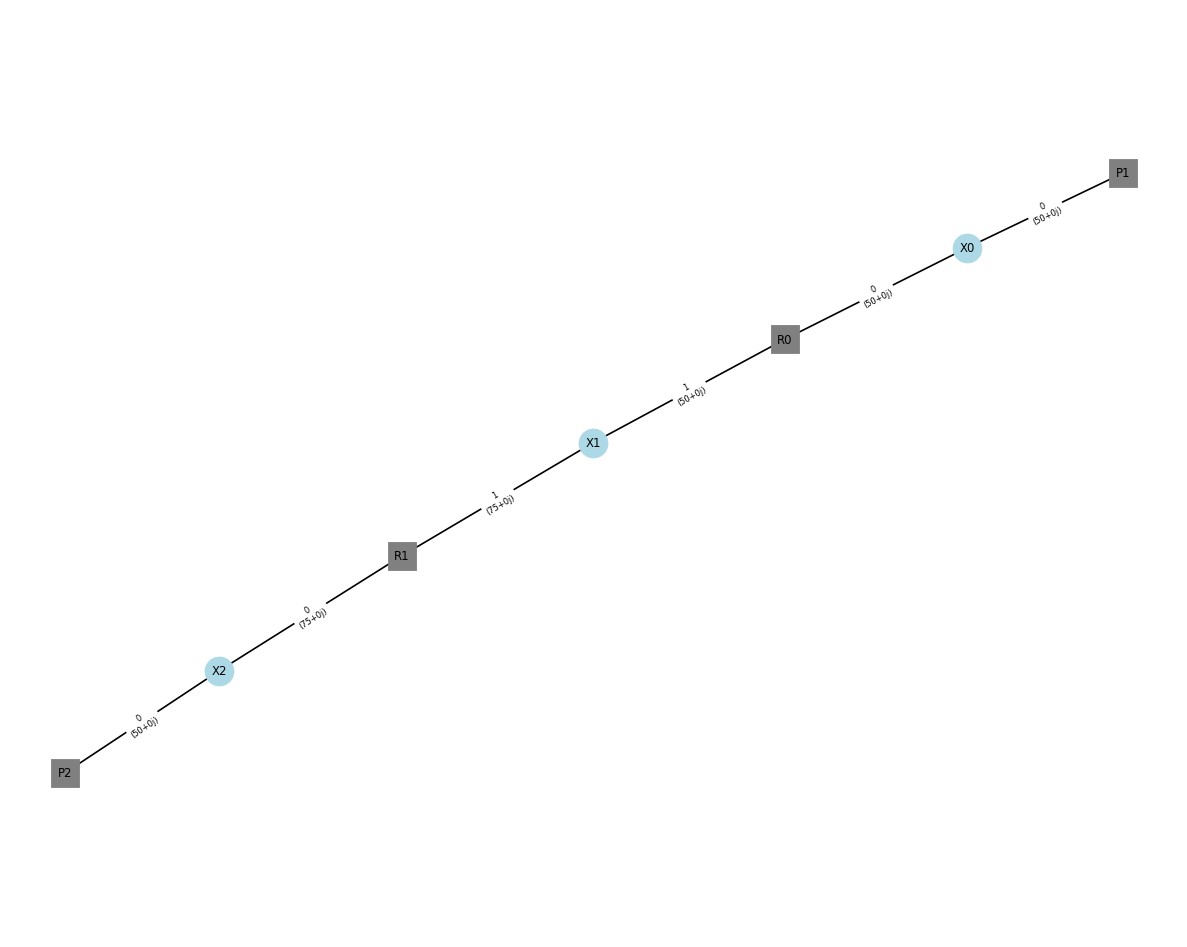

In [5]:
# Make a simple ciruit of a resistor only
#simple circuit
Rconnections = [
    [(port1, 0), (R0, 0)],
    [(R0, 1), (R1, 1)],
    [(R1, 0), (port2, 0)]
]
Rcircuit = Circuit(Rconnections)
Rcircuit.plot_graph(network_labels=True,edge_labels=True,port_labels=True,inter_labels=True)

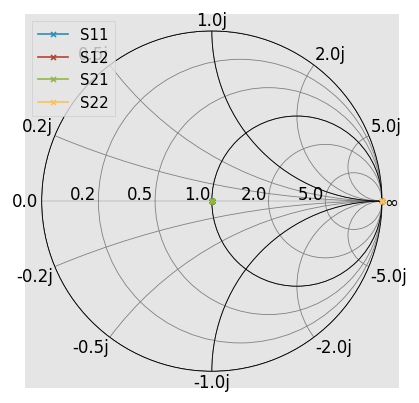

In [6]:
# show the smith chart for the above. 
# https://scikit-rf.readthedocs.io/en/latest/api/generated/skrf.network.Network.plot_s_smith.html
Rcircuit.network.plot_s_smith(draw_labels=True,marker='x')